## Cross-sport injury-risk classification — Fedor Sukhoi

### 1. Data cleaning and exploration

This notebook is the first building block to understanding the data set I was working with, because it's not the most intuitive one

### 1.1 Load the data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
SPORTS = ['Football', 'Basketball', 'Track']
TARGET = 'injury_occurred'
LABELS = {0: 'Healthy', 1: 'Low Risk', 2: 'High Risk/Injured'}
SURFACES = {0: 'Grass', 1: 'Turf', 2: 'Indoor', 3: 'Track', 4: 'Other'}

# Support launching from this folder or the parent course folder.
project_dir = Path.cwd()
if not (project_dir / 'multimodal_sports_injury_dataset.csv').exists():
    project_dir = project_dir / 'final_proj'
raw = pd.read_csv(project_dir / 'multimodal_sports_injury_dataset.csv')
# Use Football for the CSV's Soccer label before summaries and filtering.
raw['sport_type'] = raw['sport_type'].str.strip().replace({'Soccer': 'Football'})

# setup
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 35)
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})

print(f'{raw.shape[0]:,} rows, {raw.shape[1]} columns')

15,420 rows, 29 columns


### 1.2 Structure and repeated observations

The most important aspect is that the dataset contains ~100 rows for each athlete. This means there are two extremely important id's.

In [2]:
metadata = ['athlete_id', 'session_id', 'sport_type', 'gender', 'age', 'bmi', TARGET]
measurements = [c for c in raw.columns if c not in metadata]

# review session duplicates and athlete/session duplicates
assert not raw.duplicated(['athlete_id', 'session_id']).any(), 'Repeated athlete/session keys.'
print('Exact duplicate rows:', raw.duplicated().sum())

# sessions and athletes in each sport
display(raw.groupby('sport_type').agg(
    sessions=('session_id', 'size'), athletes=('athlete_id', 'nunique')
))

# sessions for each athlete
display(raw.groupby('athlete_id').size().describe().round(2).to_frame('Sessions per athlete'))

quality = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(),
                        'missing_pct': raw.isna().mean().mul(100), 'unique': raw.nunique()})
display(quality.round(2))

Exact duplicate rows: 0


,sessions,athletes
sport_type,,
Basketball,4059,41
Football,4837,49
Other,2377,24
Track,4147,42


,Sessions per athlete
count,156.00
mean,98.85
std,0.85
min,98.00
25%,98.00
50%,99.00
75%,99.00
max,101.00


,dtype,missing,missing_pct,unique
athlete_id,int64,0,0.0,156
heart_rate,float64,354,2.3,14455
body_temperature,float64,0,0.0,15173
hydration_level,float64,385,2.5,14379
sleep_quality,float64,493,3.2,14239
recovery_score,float64,0,0.0,15068
stress_level,float64,0,0.0,14832
muscle_activity,float64,570,3.7,14281
joint_angles,float64,0,0.0,14789
gait_speed,float64,431,2.8,14173


### 1.3 Light cleaning

Exclude unspecified `Other` sports. Keep missing measurements and unusual ranges for now; imputation will be fitted inside training folds.

In [3]:
df = raw.copy()

# clean up string columns
for col in ['sport_type', 'gender']:
    df[col] = df[col].astype('string').str.strip()

# checks for valid values in categorical columns
assert df['playing_surface'].isin(SURFACES).all(), 'Unknown playing-surface code.'
assert df[TARGET].isin(LABELS).all(), 'Unknown or missing target label.'

df['playing_surface'] = df['playing_surface'].map(SURFACES).astype('category')
df['gender'] = df['gender'].astype('category')
df = df.loc[df['sport_type'].isin(SPORTS)].copy() # mainly excluding 'other' as a sport type
df['sport_type'] = pd.Categorical(df['sport_type'], categories=SPORTS)

print(f'Excluded {len(raw) - len(df):,} sessions')
print(f'Retained {len(df):,} sessions from {df.athlete_id.nunique()} athletes')

Excluded 2,377 sessions
Retained 13,043 sessions from 132 athletes


### 1.4 Class balance

These are session risk labels, not counts of confirmed injury events.

,Healthy,Low Risk,High Risk/Injured
sport_type,,,
Football,3058,1037,742
Basketball,2602,876,581
Track,2668,837,642


,Healthy,Low Risk,High Risk/Injured
sport_type,,,
Football,63.22,21.44,15.34
Basketball,64.10,21.58,14.31
Track,64.34,20.18,15.48


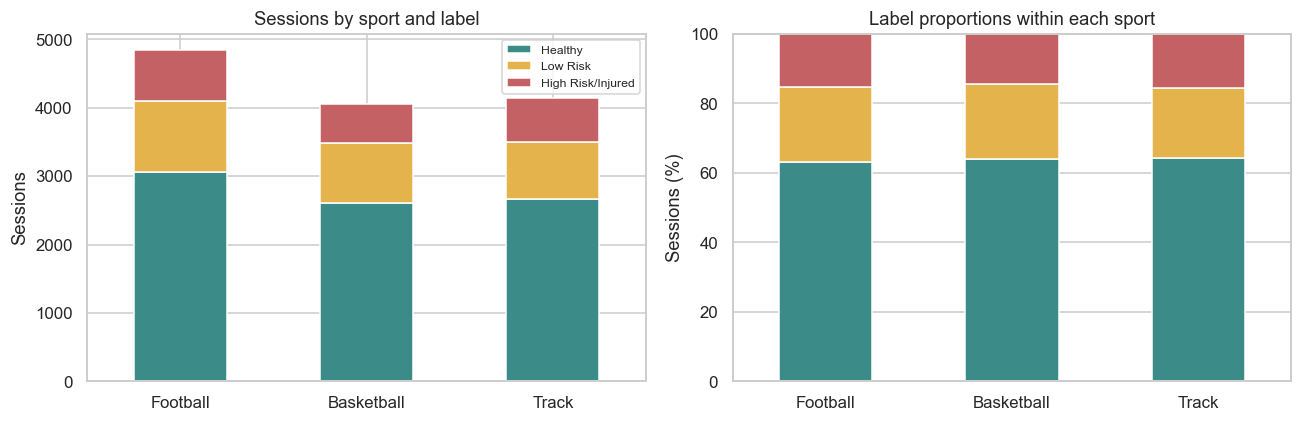

In [ ]:
label_counts = pd.crosstab(df['sport_type'], df[TARGET]).reindex(index=SPORTS, columns=list(LABELS), fill_value=0)
label_counts.columns = [LABELS[c] for c in label_counts.columns]
# Divide each sport's counts by its own session total.
label_pct = label_counts.div(label_counts.sum(axis=1), axis=0).mul(100)
display(label_counts)
display(label_pct.round(2))

# set up absolute and relative stacked bar plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ['#3b8c88', '#e4b34b', '#c46164']
label_counts.plot.bar(stacked=True, ax=axes[0], color=colors, rot=0)
label_pct.plot.bar(stacked=True, ax=axes[1], color=colors, rot=0, legend=False)
axes[0].set(title='Sessions by sport and label', ylabel='Sessions', xlabel='')
axes[1].set(title='Label proportions within each sport', ylabel='Sessions (%)', xlabel='', ylim=(0, 100))
axes[0].legend(title='', fontsize=8)
fig.tight_layout()
plt.show()

Healthy makes up roughly 64% of sessions in each sport. This instantly rings a bell to use F1 alongside accuracy.

### 1.5 Missing values

There are missing values for some important metrics, but nothing that would significantly affect the process

,missing,missing_pct
training_intensity,541,4.15
muscle_activity,485,3.72
sleep_quality,416,3.19
gait_speed,362,2.78
hydration_level,332,2.55
heart_rate,301,2.31


,training_intensity,muscle_activity,sleep_quality,gait_speed,hydration_level,heart_rate
sport_type,,,,,,
Football,4.51,3.68,3.20,2.63,2.50,2.21
Basketball,4.24,4.19,3.10,2.96,2.86,2.46
Track,3.64,3.30,3.26,2.77,2.29,2.27


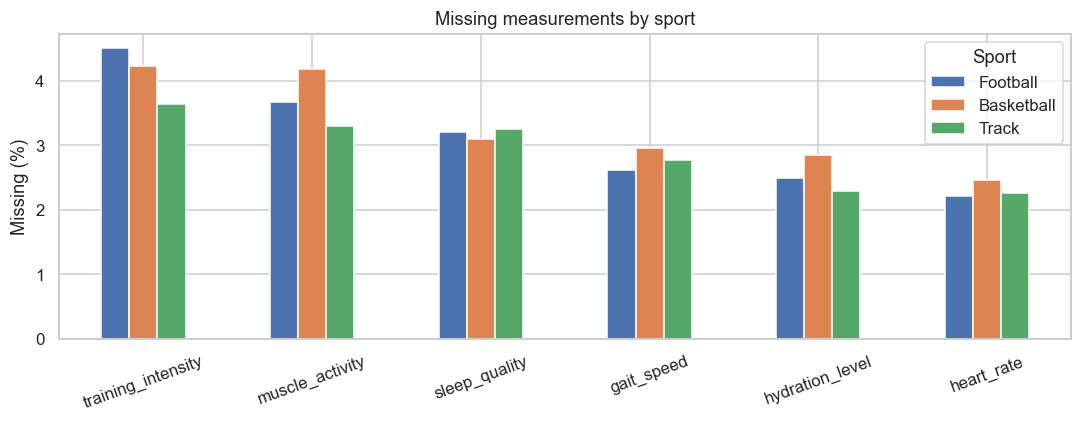

In [ ]:
# missingness
missing_pct = df[measurements].isna().mean().mul(100).sort_values(ascending=False)
missing_cols = missing_pct[missing_pct.gt(0)].index.tolist()

# missingness separately within each sport.
missing_by_sport = df.groupby('sport_type', observed=True)[missing_cols].agg(lambda x: x.isna().mean() * 100)

display(pd.DataFrame({'missing': df[missing_cols].isna().sum(),
                      'missing_pct': missing_pct[missing_cols]}).round(2))
display(missing_by_sport.round(2))

# plot missingness by sport
ax = missing_by_sport.T.plot.bar(figsize=(10, 4), rot=20)
ax.set(title='Missing measurements by sport', ylabel='Missing (%)', xlabel='')
ax.legend(title='Sport')
plt.tight_layout()
plt.show()

### 1.6 Ranges

There were publisher's limits specified on Kaggle, but upon inspection, they did not match the actual data. It's not something that changes any processes now, but I had to document it, so that if I later encounter anything extraordinary, I can reutrn here and inspect further. 

In [ ]:
# what Kaggle documentation claims
documented_ranges = {'sleep_quality': (2, 10), 'recovery_score': (25, 98),
                     'training_load': (150, 1800), 'fatigue_index': (15, 85)}

# actual numbers
range_rows = []
for feature, (low, high) in documented_ranges.items():
    values = df[feature]
    range_rows.append({'feature': feature, 'documented_min': low, 'documented_max': high,
                       'observed_min': values.min(), 'observed_max': values.max(),
                       'below_min': values.lt(low).sum(), 'above_max': values.gt(high).sum()})

range_check = pd.DataFrame(range_rows).set_index('feature')

display(range_check.round(3))
display(df.select_dtypes(include='number').drop(columns=['athlete_id', 'session_id', TARGET])
        .describe().T.round(2))

,documented_min,documented_max,observed_min,observed_max,below_min,above_max
feature,,,,,,
sleep_quality,2,10,1.156,10.000,143,0
recovery_score,25,98,8.903,98.000,356,0
training_load,150,1800,150.000,2632.638,0,33
fatigue_index,15,85,15.000,270.193,0,1918


,count,mean,std,min,25%,50%,75%,max
heart_rate,12742.0,72.55,17.74,40.00,59.85,72.15,84.63,159.27
body_temperature,13043.0,37.11,0.59,35.80,36.71,37.11,37.51,39.20
hydration_level,12711.0,78.00,11.87,45.00,69.81,78.15,86.45,100.00
sleep_quality,12627.0,5.82,1.81,1.16,4.51,5.76,7.06,10.00
recovery_score,13043.0,55.17,17.30,8.90,42.34,54.38,67.36,98.00
stress_level,13043.0,0.42,0.17,0.10,0.30,0.42,0.54,0.95
muscle_activity,12558.0,247.41,127.35,10.00,158.51,245.62,333.95,722.54
joint_angles,13043.0,112.47,30.46,45.00,91.18,112.70,134.03,175.00
gait_speed,12681.0,1.86,0.60,0.80,1.43,1.85,2.28,3.50
cadence,13043.0,86.76,24.33,50.00,67.94,85.63,103.39,185.94


### 1.7 Feature distributions by sport

I wanted to check if there are any irregularities or unusual patterns creating differences between sports.

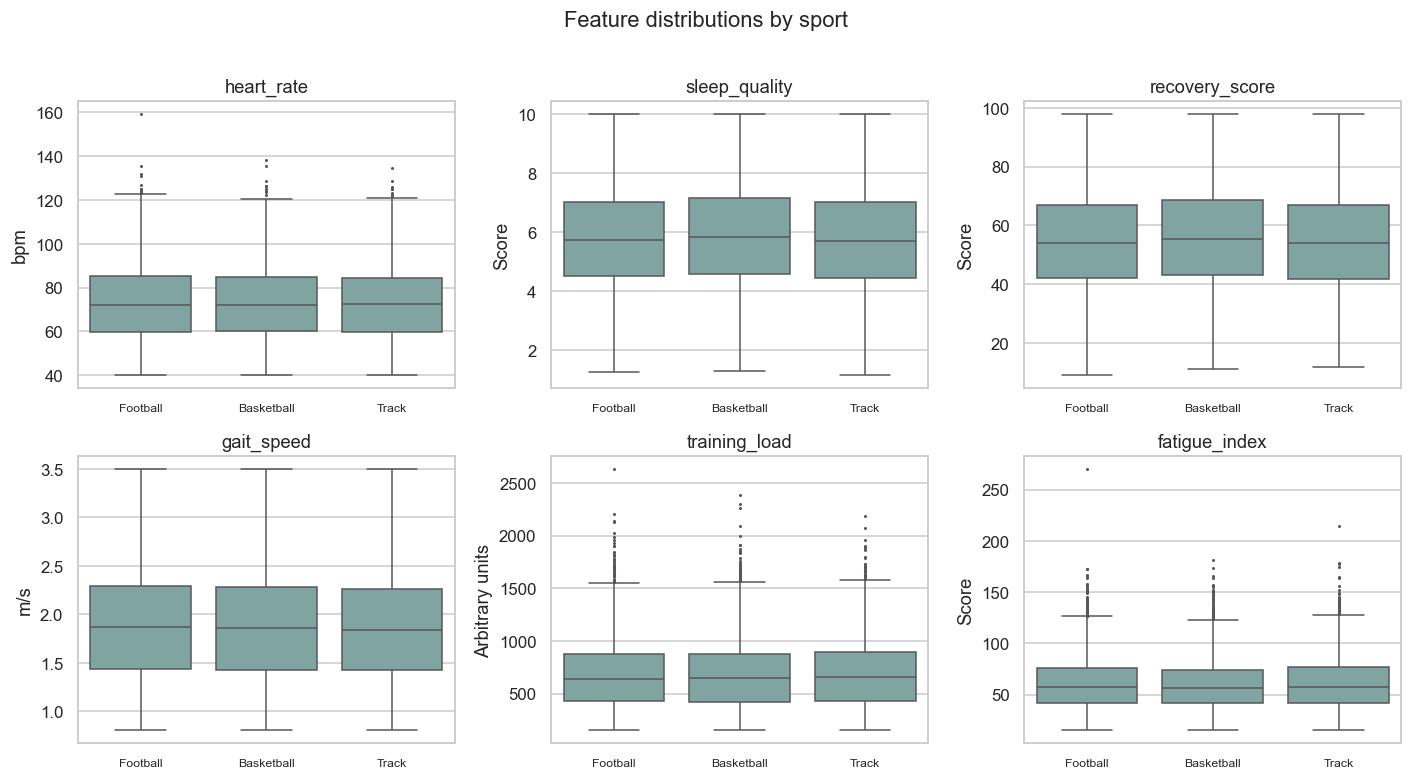

In [ ]:
# some of the most important features (just by my feeling)
features_to_plot = ['heart_rate', 'sleep_quality', 'recovery_score',
                    'gait_speed', 'training_load', 'fatigue_index']

units = {'heart_rate': 'bpm', 'sleep_quality': 'Score', 'recovery_score': 'Score',
         'gait_speed': 'm/s', 'training_load': 'Arbitrary units', 'fatigue_index': 'Score'}

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
# axes.flat lets one loop fill the 2 × 3 grid.
for feature, ax in zip(features_to_plot, axes.flat):
    sns.boxplot(data=df, x='sport_type', y=feature, order=SPORTS,
                color='#79aaa7', fliersize=1, ax=ax)
    ax.set(title=feature, xlabel='', ylabel=units[feature])
    ax.tick_params(axis='x', labelsize=8)
fig.suptitle('Feature distributions by sport', y=1.01)
fig.tight_layout()
plt.show()

Only some singular outliers pop out, but the overall boxes for all visuals are close to each other.

### 1.8 Demographics and playing surface

,athletes,age_mean,age_sd,bmi_mean,bmi_sd
sport_type,,,,,
Football,49,24.35,4.24,23.30,2.43
Basketball,41,23.12,3.23,23.53,2.41
Track,42,24.33,4.00,22.91,2.24


gender,Female,Male
sport_type,,
Football,20,29
Basketball,13,28
Track,10,32


playing_surface,Grass,Indoor,Other,Track,Turf
sport_type,,,,,
Football,19.58,19.97,19.85,20.65,19.95
Basketball,19.64,20.67,19.96,19.91,19.83
Track,18.40,19.97,20.91,19.99,20.74


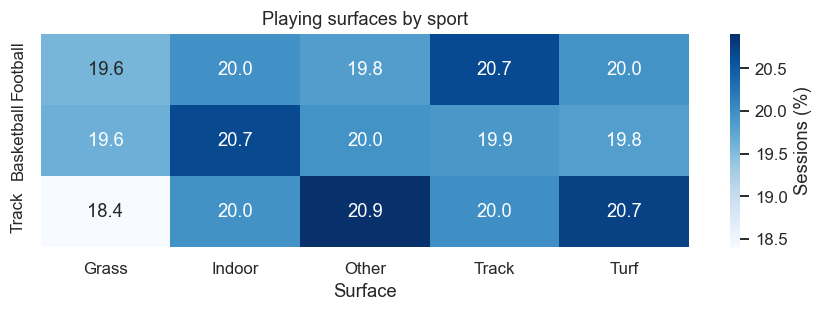

In [8]:
# Count demographics once per athlete, surfaces once per session.
athletes = df[['athlete_id', 'sport_type', 'gender', 'age', 'bmi']].drop_duplicates('athlete_id')
demographics = athletes.groupby('sport_type', observed=True).agg(
    athletes=('athlete_id', 'size'), age_mean=('age', 'mean'), age_sd=('age', 'std'),
    bmi_mean=('bmi', 'mean'), bmi_sd=('bmi', 'std')
)
display(demographics.round(2))
display(pd.crosstab(athletes['sport_type'], athletes['gender']))
surface_pct = pd.crosstab(df['sport_type'], df['playing_surface'], normalize='index').mul(100)
display(surface_pct.round(2))
fig, ax = plt.subplots(figsize=(8, 3))
sns.heatmap(surface_pct, annot=True, fmt='.1f', cmap='Blues', ax=ax, cbar_kws={'label': 'Sessions (%)'})
ax.set(title='Playing surfaces by sport', xlabel='Surface', ylabel='')
fig.tight_layout()
plt.show()

Surfaces are almost uniformly distributed across sports, including Grass and Turf for Basketball. To be honest, that is questionable, but likely that is due to training sessions being not only specific sport-tailored. 

### 1.9 Modeling inputs

In [10]:
# Keep IDs and sport separate for experiment-specific splitting.
X = df.drop(columns=['athlete_id', 'session_id', 'sport_type', TARGET])
y = df[TARGET]
groups = df['athlete_id']
sports = df['sport_type']
categorical_features = X.select_dtypes(include=['category', 'string', 'object']).columns.tolist()
numeric_features = [c for c in X.columns if c not in categorical_features]

print('Predictors:', X.shape)
print('Categorical:', categorical_features)
print('Missing predictor cells:', X.isna().sum().sum())

Predictors: (13043, 25)
Categorical: ['playing_surface', 'gender']
Missing predictor cells: 2437


### Splits will depend on the goal

- **A:** hold out athletes within each sport; keep all their sessions together.
- **B–D:** train on all athletes from two sports, test on all athletes from the third.